# 01 · Time response

The response of a linear system to an input is the convolution of the input with the impulse response, and
the state evolves by the matrix exponential: x(t) = e^{At} x₀ + ∫ e^{A(t−τ)} B u(τ) dτ. This notebook
computes responses exactly on a time grid, reads the step response's characteristics (rise, peak, overshoot,
settling), derives them for the second-order prototype, shows the dominant-pole approximation and the effect
of zeros, and connects steady-state error to system type.

**What you will learn**
- compute exact responses with the matrix exponential
- read rise time, overshoot and settling time and derive them for the second-order prototype
- apply the dominant-pole approximation and anticipate the effect of zeros
- relate steady-state error to system type

**Before you start:** notebook 00  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, response as rs, models, linalg as la
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The exact response on a grid: the matrix exponential

In [2]:
A = np.array([[0.0, 1.0], [-4.0, -1.2]])          # the prototype wn = 2, zeta = 0.3
B = np.array([[0.0], [4.0]]); C = np.array([[1.0, 0.0]])
h = 0.01
Phi, Gamma = la.expm_with_integral(A, B, h)        # one matrix exponential of the augmented matrix gives both
print("Phi = e^{Ah} =\n", np.round(Phi, 6), "\nGamma = int_0^h e^{At} dt B =", np.round(Gamma.ravel(), 6))
x = np.zeros(2); ys = []
for k in range(1000):
    ys.append((C @ x)[0]); x = Phi @ x + Gamma.ravel() * 1.0       # unit step
t = np.arange(1000) * h
t2, y2 = rs.step(sy.ss(A, B, C, 0.0), 9.99, 1000)
print("hand-rolled recursion vs library step response:", f"{np.max(np.abs(np.array(ys) - y2)):.1e}")

Phi = e^{Ah} =
 [[ 0.999801  0.00994 ]
 [-0.039758  0.987873]] 
Gamma = int_0^h e^{At} dt B = [0.000199 0.039758]
hand-rolled recursion vs library step response: 0.0e+00


For a piecewise-constant input the solution is *exact* at the sample instants: x_{k+1} = Φ x_k + Γ u_k with
Φ = e^{Ah} and Γ = ∫₀ʰ e^{At} dt B, both obtained from one exponential of the augmented matrix [[A, B], [0, 0]]
(Van Loan's trick). No ODE solver, no step-size error: the library's responses are computed this way, and the
same formulas are the zero-order-hold discretisation of notebook 12.

## The second-order prototype and its formulas

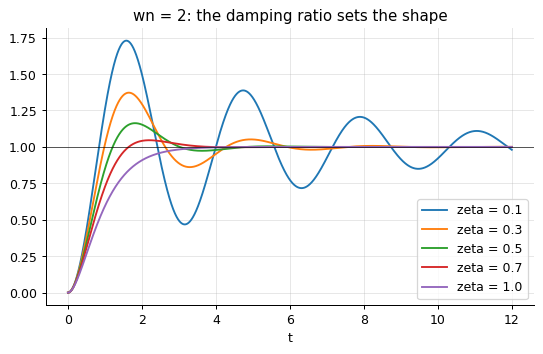

 zeta  overshoot %  exp(-pi z/sqrt(1-z^2)) %  peak time  pi/wd  settling (2 %)  4/(zeta wn)  rise time
0.100       72.925                    72.925      1.578  1.579          11.786       20.000      0.552
0.300       37.233                    37.233      1.646  1.647           5.616        6.667      0.660
0.500       16.303                    16.303      1.814  1.814           4.040        4.000      0.818
0.700        4.599                     4.599      2.200  2.200           2.990        2.857      1.062
1.000        0.000                     0.000     12.000    NaN           2.918          NaN      1.680


In [3]:
rows = []
for zeta in (0.1, 0.3, 0.5, 0.7, 1.0):
    G = sy.tf([4.0], [1.0, 4 * zeta, 4.0])
    t, y = rs.step(G, 12.0, 6001)
    info = rs.step_info(t, y, final=G.dcgain())
    th = rs.second_order(zeta, 2.0) if zeta < 1 else {"overshoot": 0.0, "peak_time": np.nan, "settling_time_2pct": np.nan}
    rows.append((zeta, info["overshoot"], th["overshoot"], info["peak_time"], th["peak_time"], info["settling_time"], th["settling_time_2pct"], info["rise_time"]))
    plt.plot(t, y, label=f"zeta = {zeta}")
plt.axhline(1, color="k", lw=0.5); plt.legend(); plt.xlabel("t"); plt.title("wn = 2: the damping ratio sets the shape"); plt.show()
print(pd.DataFrame(rows, columns=["zeta", "overshoot %", "exp(-pi z/sqrt(1-z^2)) %", "peak time", "pi/wd", "settling (2 %)", "4/(zeta wn)", "rise time"]).to_string(index=False, float_format="%.3f"))

The prototype ω_n²/(s² + 2ζω_n s + ω_n²) is the whole vocabulary of transient response: the measured overshoot
equals exp(−πζ/√(1−ζ²)) and the peak time π/ω_d to all digits, while the "4/(ζω_n)" settling time is only an
estimate (it assumes the envelope alone matters; the actual 2 % settling time jumps between oscillation cycles,
as the ζ = 0.7 row shows). These formulas run the other way too: a specification of 10 % overshoot and 1 s
settling is a region of the s-plane (ζ ≥ 0.59, σ ≥ 4), the target of every placement design.

## Dominant poles and the effect of zeros

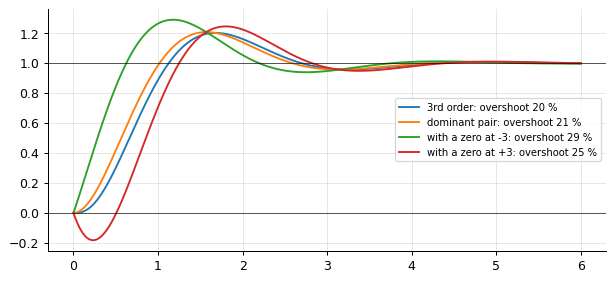

dominant poles of G3: [-1.+2.j -1.-2.j]


In [4]:
G3 = sy.zpk([], [-1 + 2j, -1 - 2j, -10.0], 50.0)              # a fast third pole
G2 = sy.zpk([], [-1 + 2j, -1 - 2j], 5.0)                        # the dominant pair alone
Gz = sy.zpk([-3.0], [-1 + 2j, -1 - 2j], 5.0 / 3)                # a zero near the pair
Gnmp = sy.zpk([3.0], [-1 + 2j, -1 - 2j], -5.0 / 3)              # a right-half-plane zero
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, g in (("3rd order", G3), ("dominant pair", G2), ("with a zero at -3", Gz), ("with a zero at +3", Gnmp)):
    t, y = rs.step(g, 6.0)
    ax.plot(t, y, label=f"{name}: overshoot {rs.step_info(t, y, final=g.dcgain())['overshoot']:.0f} %")
ax.axhline(1, color="k", lw=0.5); ax.axhline(0, color="k", lw=0.5); ax.legend(fontsize=8); plt.show()
print("dominant poles of G3:", np.round(rs.dominant_poles(G3), 3))

A pole ten times further from the imaginary axis than the dominant pair barely changes the response (its mode
decays in a tenth of the time), which is why second-order formulas serve for higher-order systems: the
*dominant* poles decide. Zeros are not so forgiving: a left-half-plane zero near the dominant poles increases
the overshoot (it adds a derivative of the response), and a right-half-plane zero produces the undershoot of
the non-minimum-phase system.

## Steady-state error and system type

In [5]:
P = sy.tf([1.0], [1.0, 3.0, 2.0])
for name, C in (("P control, K = 5 (type 0)", sy.tf([5.0], [1.0])), ("PI control (type 1)", sy.tf([5.0, 5.0], [1.0, 0.0]))):
    T = sy.feedback(sy.series(C, P))
    t, y = rs.step(T, 15.0)
    u_ramp = t
    _, y_ramp, _ = rs.lsim(T, u_ramp, t)
    print(f"{name:<28}: step error {1 - y[-1]:+.4f} (1/(1 + Kp) = {1 / (1 + 5 * P.dcgain()):.4f} for type 0), ramp error at t = 15: {u_ramp[-1] - y_ramp[-1]:.4f}")

P control, K = 5 (type 0)   : step error +0.2857 (1/(1 + Kp) = 0.2857 for type 0), ramp error at t = 15: 4.5972
PI control (type 1)         : step error -0.0000 (1/(1 + Kp) = 0.2857 for type 0), ramp error at t = 15: 0.4075


With proportional control of a type-0 plant the step error is 1/(1 + K_p) - a finite offset - and a ramp runs
away. One integrator in the loop (type 1) drives the step error to zero and leaves a finite ramp error 1/K_v.
The system type counts the integrators in the open loop; the final-value theorem turns it into the steady-state
error for each test input. Integral action is the cure for offsets, at a cost in phase margin that notebook 06
measures.

## Inside the algorithm: the step response of the prototype in closed form

In [6]:
zeta, wn = 0.3, 2.0
wd = wn * np.sqrt(1 - zeta**2)
tt = np.linspace(0, 10, 1001)
y_formula = 1 - np.exp(-zeta * wn * tt) * (np.cos(wd * tt) + zeta / np.sqrt(1 - zeta**2) * np.sin(wd * tt))
_, y_lib = rs.step(sy.tf([4.0], [1.0, 1.2, 4.0]), 10.0, 1001)
print("closed-form step response vs the matrix-exponential computation:", f"{np.max(np.abs(y_formula - y_lib)):.1e}")

closed-form step response vs the matrix-exponential computation: 6.4e-15


## Exercises
1. For the DC motor, find the voltage step response's rise time and settling time and relate them to the two time constants. Then double the inertia J and repeat: which time constant moved?
2. A specification asks for overshoot < 10 % and 2 % settling < 1 s. Draw the allowed region of the s-plane (zeta and sigma bounds) and check it with three pole pairs of your choice by simulation.
3. **Implement it yourself:** compute the impulse response of the prototype from the initial-condition response with x0 = B (no input) and compare with `response.impulse`; explain why they are the same.